# Comprar y mantener con retiro gradual vs Nov–Jun

**Laboratorio reproducible, no historial real de cuenta ni recomendación financiera.** Reconstrucción retrospectiva con los **pesos actuales indicados por Alejandro**, sujeta a **sesgo de supervivencia y retrospectivo**: los pesos actuales no prueban lo que se hizo durante la década.

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Andalejo1109/inversion-largo-plazo-vs-market-timing/blob/main/notebooks/analisis.ipynb)

**Supuestos fiscales educativos aportados por el usuario:** B&H 15% ganancia ocasional simplificado para el plan; Nov–Jun 19%/33% ganancia ordinaria. No son tarifas universales ni asesoría fiscal. El modelo calcula en USD, no realiza una declaración fiscal en COP.

**Qué muestra:** impuestos sobre la ganancia (no capital), retiro anual al cierre de diciembre, retención del cash recibido al 0%, patrimonio económico —no liquidación neta—, coste original y ganancias latentes.

## 1. Datos, fechas y pesos: fijar antes de calcular

El Parquet incorpora adjusted close de Yahoo obtenido con yfinance, **splits y distribuciones incorporados**. Su tratamiento equivale a reinversión de dividendos, sin impuestos fiscales de dividendos separados. BRK.B se consulta como `BRK-B`. Datos offline del cache público; no hay credenciales ni cuenta real.

In [1]:
from pathlib import Path
import sys, json, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src import config
from src.engine import run_strategy, benchmark_returns, first_on_or_after, last_on_or_before, annual_withdrawal_dates, row_prices, xirr

prices=pd.read_parquet(ROOT/'cache/yfinance_adjusted_close.parquet')
weights=config.WEIGHTS
period=prices.loc[config.START:,list(weights)]
print(f'Cierre ajustado: {prices.index.min().date()} → {prices.index.max().date()}')
print(f'Backtest: {period.index[0].date()} → {period.index[-1].date()}; última fecha completa, sin liquidar')
print('Sin nulos:',not prices.isna().any().any(),'| observaciones:',len(prices))
pd.DataFrame({'Activo':list(weights),'Peso actual':pd.Series(weights)}).assign(**{'Peso %':lambda x:x['Peso actual']*100})

Cierre ajustado: 2015-10-01 → 2026-11-05
Backtest: 2016-11-01 → 2026-11-05; última fecha completa, sin liquidar
Sin nulos: True | observaciones: 2791


,Activo,Peso actual,Peso %
SPYG,SPYG,0.31,31.0
SMH,SMH,0.22,22.0
BRK-B,BRK-B,0.20,20.0
IEMG,IEMG,0.20,20.0
VTI,VTI,0.07,7.0


**Periodo de cálculo efectivo:** 1-nov-2016 a 5-nov-2026. Aportes DCA: **$34.000** ($10.000 iniciales + 120 contribuciones mensuales de $200 al primer día bursátil del mes). El lump aporta solo **$10.000**: se expone aparte, no como igualdad de fondos invertidos.

Comisiones de despliegue: `cash × b/(10.000+b)` con b=5. Cash de Nov–Jul ajustado bien: venta en junio, permanencia cash julio–octubre al 0%. Fracciones admitidas.

In [2]:
first_contribution=pd.Timestamp(config.START)
monthly_dates=pd.date_range(config.START,period.index.max(),freq='MS')
total_dca=config.INITIAL_CAPITAL+config.MONTHLY_CONTRIBUTION*len(monthly_dates)
contribution_comparison=pd.DataFrame({
 'Plan':['DCA','Lump'],
 'Aporte inicial':[config.INITIAL_CAPITAL,config.INITIAL_CAPITAL],
 'Aportes mensuales':[config.MONTHLY_CONTRIBUTION*len(monthly_dates),0],
 'Dólares aportados':[total_dca,config.INITIAL_CAPITAL],
 'Aportes mensuales N':[len(monthly_dates),0]})
print('Retiros: diciembre 2018–2025, sin retiro anticipado 2026')
print(annual_withdrawal_dates(prices,period.index))
contribution_comparison

Retiros: diciembre 2018–2025, sin retiro anticipado 2026
[Timestamp('2018-12-31 00:00:00'), Timestamp('2019-12-31 00:00:00'), Timestamp('2020-12-31 00:00:00'), Timestamp('2021-12-31 00:00:00'), Timestamp('2022-12-30 00:00:00'), Timestamp('2023-12-29 00:00:00'), Timestamp('2024-12-31 00:00:00'), Timestamp('2025-12-31 00:00:00')]


,Plan,Aporte inicial,Aportes mensuales,Dólares aportados,Aportes mensuales N
0,DCA,10000.0,24200.0,34200.0,121
1,Lump,10000.0,0.0,10000.0,0


## 2. Motor contable visible: separar coste, ganancia y principal

Compra por activo i:
\[
 q_i \mathrel{+}=w_i C(1-c)/P_i,\qquad B=\sum_i q_i b_i
\]
donde \(q_i\) son unidades y \(b_i\) es coste medio por unidad tras cada compra. El coste de una venta proporcional es \(q_{v,i}b_i\).

**En cada venta global:** \(G=\max(0,V_{neto}-\sum_i q_{v,i}b_i)\) y \(\mathbf{T=tasa	imes G}\). Cambiar de versión a agregación global permite neutralizar ganancias/pérdidas dentro de la misma venta. Sin base positiva no hay tax. Nunca `tax_rate × gross_proceeds`.

Demostración en dos activos y dos sesiones, sin asociar resultados a un emisor real.

In [3]:
# Actualización del coste promedio: 50% de aporte por activo.
qty=pd.Series({'Activo A':0.,'Activo B':0.})
cost_per_unit=pd.Series({'Activo A':0.,'Activo B':0.})
price={'Activo A':100.,'Activo B':100.}
capital=10_000.; fee_ratio=5/(10000+5); alloc=capital*(1-fee_ratio)*.5
qty+=pd.Series({'Activo A':alloc/100.,'Activo B':alloc/100.})
cost_per_unit[:]=alloc/qty

# Venta al 50%: se venden unidades, pero no por el 50% del patrimonio.
fraction=0.50; units_sold=qty*fraction
sale_prices=pd.Series({'Activo A':130.,'Activo B':100.})
proceeds_by_asset=units_sold*sale_prices*(1-.0005)
basis_sold=units_sold*cost_per_unit
V=proceeds_by_asset.sum(); basis=basis_sold.sum()
gain=max(0.,V-basis); tax=.15*gain
answer=pd.DataFrame({'Bruto':[float((units_sold*sale_prices).sum())],
                     'Coste vendido (no imponible)':[basis],
                     'Proceeds neto de fee':[V],
                     'Ganancia fiscal max(0,V-basis)':[gain],
                     'Impuesto 15% de ganancia':[tax],
                     'Cash distribuido neto':[float((units_sold*sale_prices).sum())*(.9995)-tax],
                     'Coste remanente en unidades':[float(((qty-units_sold)*cost_per_unit).sum())]})
assert np.isclose(tax,.15*max(0,V-basis))
answer.T.rename(columns={0:'USD'})

,USD
Bruto,5747.126437
Coste vendido (no imponible),4997.501249
Proceeds neto de fee,5744.252874
"Ganancia fiscal max(0,V-basis)",746.751624
Impuesto 15% de ganancia,112.012744
Cash distribuido neto,5632.240130
Coste remanente en unidades,4997.501249


## 3. Plan de retiro B&H: 10% de ganancia, no 10% del patrimonio

En **último cierre disponible de cada diciembre, 2018–2025**:
\[
U=V-B,\qquad W_{bruto}=10\%\max(0,U).
\]
Las fechas son 31-dic-2018/2019/2020/2021, **30-dic-2022**, **29-dic-2023**, 31-dic-2024/2025. No hay retiro de diciembre de 2026 porque termina el sample el 5-nov.

La regla permite dimensionar el retiro usando la **ganancia acumulada**, pero cobrarlo exige venta parcial proporcional: **incluye coste y ganancia**, no vende “ganancia pura”. Si gana positivo global solo la parte \(V_{neto}-B_{vendido}\) paga 15%.

**Simplificación fiscal material:** B&H DCA aplica el trato de holding ≥2 años a nivel del plan, sin antigüedad por lote. Hay aportes recientes de menos de dos años. Es una **sensibilidad educativa**, no una determinación tributaria real.

El siguiente bloque llama al motor con parámetros explícitos; la primera celda de cálculos ya muestra su lógica de contabilidad. Los detalles diarios se pueden examinar en `src/engine.py`, y todos los eventos reales se exportan aquí para inspección.

In [4]:
from run_backtest import primary_results
results=primary_results(prices)
metrics=pd.DataFrame([r.summary for r in results]).set_index('name')

def events(name,event):
    return next(r for r in results if r.name==name).events.query('event==@event').copy()

withdrawals=pd.concat([events('core_bh_dca_withdraw_10pct_gains_15','annual_gain_withdrawal').assign(Plan='DCA'),
                       events('core_bh_lump_withdraw_10pct_gains_15','annual_gain_withdrawal').assign(Plan='Lump')])
flat_sales=pd.concat([events('core_nov_jun_tax_19','seasonal_full_sale').assign(Tax=.19),
                      events('core_nov_jun_tax_33','seasonal_full_sale').assign(Tax=.33)])

print('¡Aquí sí hay un evento por diciembre 2018–2025!')
w=withdrawals[withdrawals.Plan=='DCA'][['date','unrealized_gain_before','gross_proceeds','unrealized_gain_before']]
w.columns=['Fecha','Ganancia no realizada U','Retiro bruto W=10%U','Referencia U']
w=pd.concat([w.drop(columns='Referencia U'), withdrawals[withdrawals.Plan=='DCA'][['cost_basis_sold','taxable_gain','tax','net_withdrawal']]],axis=1)
w.rename(columns={'cost_basis_sold':'Coste en venta no imponible','taxable_gain':'Ganancia fiscal','tax':'Tax a 15%','net_withdrawal':'Cash neto'}).round(2)

¡Aquí sí hay un evento por diciembre 2018–2025!


/tmp/ipykernel_24434/2110515966.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  w.rename(columns={'cost_basis_sold':'Coste en venta no imponible','taxable_gain':'Ganancia fiscal','tax':'Tax a 15%','net_withdrawal':'Cash neto'}).round(2)


,Fecha,Ganancia no realizada U,Retiro bruto W=10%U,Coste en venta no imponible,Ganancia fiscal,Tax a 15%,Cash neto
26,2018-12-31,3074.13,307.41,255.11,52.15,7.82,299.44
39,2019-12-31,9021.28,902.13,591.00,310.68,46.60,855.08
52,2020-12-31,17067.30,1706.73,897.84,808.04,121.21,1584.67
65,2021-12-31,26691.72,2669.17,1157.72,1510.12,226.52,2441.32
78,2022-12-30,14222.20,1422.22,858.92,562.59,84.39,1337.12
91,2023-12-29,26872.39,2687.24,1245.82,1440.07,216.01,2469.88
104,2024-12-31,40661.85,4066.19,1524.11,2540.04,381.01,3683.15
117,2025-12-31,57617.01,5761.70,1755.79,4003.03,600.45,5158.37


In [5]:
# Prueba literal de la fórmula sobre los eventos RECALCULADOS, no solo valores copiados.
wcheck=(withdrawals.gross_proceeds-.10*withdrawals.unrealized_gain_before).abs().max()
taxcheck_dca=(withdrawals[withdrawals.Plan=='DCA'].tax-.15*withdrawals[withdrawals.Plan=='DCA'].taxable_gain).abs().max()
taxcheck_nj=max((flat_sales.tax-flat_sales.Tax*flat_sales.taxable_gain).abs().max(),0)
print('Máxima diferencia |W-0.10×U|:',wcheck)
print('Máxima diferencia tax B&H - 15%×gain:',taxcheck_dca)
print('Máxima diferencia tax Nov-Jun - tasa×gain:',taxcheck_nj)
assert max(wcheck,taxcheck_dca,taxcheck_nj)<1e-7
print('Ninguna venta tiene base fiscal negativa:',(flat_sales.taxable_gain>=0).all())
print('¿Se cobra principal?',not bool((withdrawals.tax>withdrawals.taxable_gain*.15+1e-7).any()))

Máxima diferencia |W-0.10×U|: 9.094947017729282e-13
Máxima diferencia tax B&H - 15%×gain: 0.0
Máxima diferencia tax Nov-Jun - tasa×gain: 0.0
Ninguna venta tiene base fiscal negativa: True
¿Se cobra principal? True


## 4. Nov–Jun: realización anual y reinicio de base

Compra el primer día bursátil desde 1 de noviembre, cierra todo el último día bursátil de junio y conserva cash al 0% en jul-oct. Cada junio vende y cobra impuesto a partir de \(B\): \(\max(0,V_{neto}-B)	imes(19\%\;\mathrm{o}\;33\%)\). En noviembre el nuevo coste se reinicia al nuevo importe neto. **Son ciclos anuales**, no los años aislados cada cuatro años del tuit: ese material puede corresponder a midterms; nuestra hipótesis es distinta. El tuit no se llama falso.

El 5-nov-2026 hay un ciclo abierto que NO se vende anticipadamente. No se aplica un impuesto terminal hipotético a B&H con retiro; su ganancia latente permanece.

In [6]:
annual_audit=flat_sales.groupby('Tax').agg(
    Ventas_junio=('date','count'),
    Pasos_positivos=('taxable_gain','count'),
    Precio_agregado=('gross_proceeds','sum'),
    Coste_agregado=('cost_basis_sold','sum'),
    Ganancia_imponible=('taxable_gain','sum'),
    Tax=('tax','sum'))
display(annual_audit.round(2))
print('\nEjemplo de venta anual y sus bases:')
flat_sales[['date','Tax','gross_proceeds','cost_basis_sold','taxable_gain','tax']].iloc[[0,1,10,11]].round(2)

,Ventas_junio,Pasos_positivos,Precio_agregado,Coste_agregado,Ganancia_imponible,Tax
Tax,,,,,,
0.19,10,10,359762.09,307421.74,58789.81,11170.06
0.33,10,10,333492.00,285458.00,54093.16,17850.74



Ejemplo de venta anual y sus bases:


/tmp/ipykernel_24434/1071996094.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  flat_sales[['date','Tax','gross_proceeds','cost_basis_sold','taxable_gain','tax']].iloc[[0,1,10,11]].round(2)


,date,Tax,gross_proceeds,cost_basis_sold,taxable_gain,tax
8,2017-06-30,0.19,13258.99,11394.30,1858.06,353.03
17,2018-06-29,0.19,15781.27,15291.68,481.69,91.52
8,2017-06-30,0.33,13258.99,11394.30,1858.06,613.16
17,2018-06-29,0.33,15511.80,15031.69,472.35,155.88


## 5. Métricas: qué es lo realizado y qué no

- **Cartera restante:** \$V al final, sin liquidar.
- **Retiros retenidos netos:** \(\sum W_{neto}=\sum(W_{bruto}-fee-T)\), guardados al 0%, no reinvertidos.
- **Patrimonio económico:** cartera + retiros netos retenidos. **No neto liquidable**; ganancias latentes y fiscalidad/costes finales no modelados.
- **XIRR:** flujo por fecha: aportes negativos, cada retiro neto positivo EN SU FECHA y cartera restante al final; resuelve `npv(r)=0` entre -0,999999 y 10.
- **Riesgo TWR:** elimina aportes y retiros del cambio de cartera para no leerlos como ganancia/pérdida de mercado.

El Yo no liquidado es un agregado económico interno con cash al cero rendimiento: no implica efectivo disponible después de liquidar al final.

In [7]:
cols=['remaining_portfolio_net','withdrawals_net','net_terminal_value','taxes_total','withdrawals_gross','xirr','final_tax_basis','final_unrealized_gain','terminal_tax']
summary=metrics[cols].rename(columns={
 'remaining_portfolio_net':'Cartera sin liquidar',
 'withdrawals_net':'Retiros netos retenidos',
 'net_terminal_value':'Patrimonio económico NO liquidado',
 'taxes_total':'Impuestos ya pagados',
 'withdrawals_gross':'Retiros brutos',
 'xirr':'XIRR',
 'final_tax_basis':'Coste total remanente',
 'final_unrealized_gain':'Ganancia latente',
 'terminal_tax':'Tax final aplicado'})
display(summary.round(4))
nov19=metrics.loc['core_nov_jun_tax_19','net_terminal_value']
nov33=metrics.loc['core_nov_jun_tax_33','net_terminal_value']
metrics['vs_Core_Nov19']=metrics.net_terminal_value-nov19
metrics['vs_Core_Nov33']=metrics.net_terminal_value-nov33
metrics[['net_terminal_value','xirr','taxes_total','vs_Core_Nov19','vs_Core_Nov33']].round(4)

,Cartera sin liquidar,Retiros netos retenidos,Patrimonio económico NO liquidado,Impuestos ya pagados,Retiros brutos,XIRR,Coste total remanente,Ganancia latente,Tax final aplicado
name,,,,,,,,,
core_bh_dca_withdraw_10pct_gains_15,90669.5421,17829.0177,108498.5598,1684.0079,19522.7870,0.1913,25696.7020,64972.8401,0.0
core_bh_lump_withdraw_10pct_gains_15,38260.0972,10413.4197,48673.5169,1165.8844,11585.0966,0.1919,6188.2609,32071.8363,0.0
core_nov_jun_tax_19,71589.0266,0.0000,71589.0266,11170.0645,0.0000,0.1121,74799.2910,-3210.2643,0.0
core_nov_jun_tax_33,61101.8788,0.0000,61101.8788,17850.7418,0.0000,0.0886,63841.8684,-2739.9895,0.0
spy_nov_jun_tax_19,56873.5992,0.0000,56873.5992,7075.8456,0.0000,0.0780,58355.5696,-1481.9705,0.0
spy_nov_jun_tax_33,50682.0793,0.0000,50682.0793,11563.7184,0.0000,0.0607,52002.7157,-1320.6364,0.0
core_bh_dca_tax_0,127543.9457,0.0000,127543.9457,0.0000,0.0000,0.1972,33983.0085,93560.9372,0.0
core_nov_jun_tax_0,88491.5544,0.0000,88491.5544,0.0000,0.0000,0.1433,92459.7782,-3968.2238,0.0
spy_nov_jun_tax_0,66457.8591,0.0000,66457.8591,0.0000,0.0000,0.1011,68189.5692,-1731.7101,0.0


,net_terminal_value,xirr,taxes_total,vs_Core_Nov19,vs_Core_Nov33
name,,,,,
core_bh_dca_withdraw_10pct_gains_15,108498.5598,0.1913,1684.0079,36909.5332,47396.6810
core_bh_lump_withdraw_10pct_gains_15,48673.5169,0.1919,1165.8844,-22915.5097,-12428.3619
core_nov_jun_tax_19,71589.0266,0.1121,11170.0645,0.0000,10487.1478
core_nov_jun_tax_33,61101.8788,0.0886,17850.7418,-10487.1478,0.0000
spy_nov_jun_tax_19,56873.5992,0.0780,7075.8456,-14715.4275,-4228.2797
spy_nov_jun_tax_33,50682.0793,0.0607,11563.7184,-20906.9474,-10419.7996
core_bh_dca_tax_0,127543.9457,0.1972,0.0000,55954.9190,66442.0668
core_nov_jun_tax_0,88491.5544,0.1433,0.0000,16902.5277,27389.6755
spy_nov_jun_tax_0,66457.8591,0.1011,0.0000,-5131.1675,5355.9803


In [8]:
bh=metrics.loc['core_bh_dca_withdraw_10pct_gains_15']
portfolio=90669.54210235663; distributions=17829.017710160348
identity=bh.remaining_portfolio_net+bh.withdrawals_net
assert abs(identity-bh.net_terminal_value)<1e-7
assert abs(portfolio+distributions-108498.55981251698)<1e-7
assert abs(bh.remaining_portfolio_net-portfolio)<1e-7
assert abs(bh.withdrawals_net-distributions)<1e-7
print(f'Identidad efectiva: {bh.remaining_portfolio_net:,.2f} + {bh.withdrawals_net:,.2f} = {identity:,.2f}')
capital_left=bh.total_contributions-bh.purchase_costs-bh.withdrawn_principal_cost_basis
print('Aportes originales netos no distribuidos:',round(capital_left,2))
print('Coste fiscal total remanente (incluye compras con cash reinvertido):',round(bh.final_tax_basis,2))
print('Ganancia no realizada latente incluida en patrimonio:',round(bh.final_unrealized_gain,2))
print('No se clasifica por lote DCA; tax final =',bh.terminal_tax)

Identidad efectiva: 90,669.54 + 17,829.02 = 108,498.56
Aportes originales netos no distribuidos: 25696.7
Coste fiscal total remanente (incluye compras con cash reinvertido): 25696.7
Ganancia no realizada latente incluida en patrimonio: 64972.84
No se clasifica por lote DCA; tax final = 0.0


## 6. Gráficos de patrimonio y retención de retiros

El valor de equity une cartera con retiros netos acumulados como cash al 0% para ser consistente con patrimonio económico. Curvas diferentes no son una evolución de la cuenta real de Alejandro. Se copian las salidas del mismo script `run_backtest.py` al directorio del archivo para facilitar enlaces dentro del repositorio.

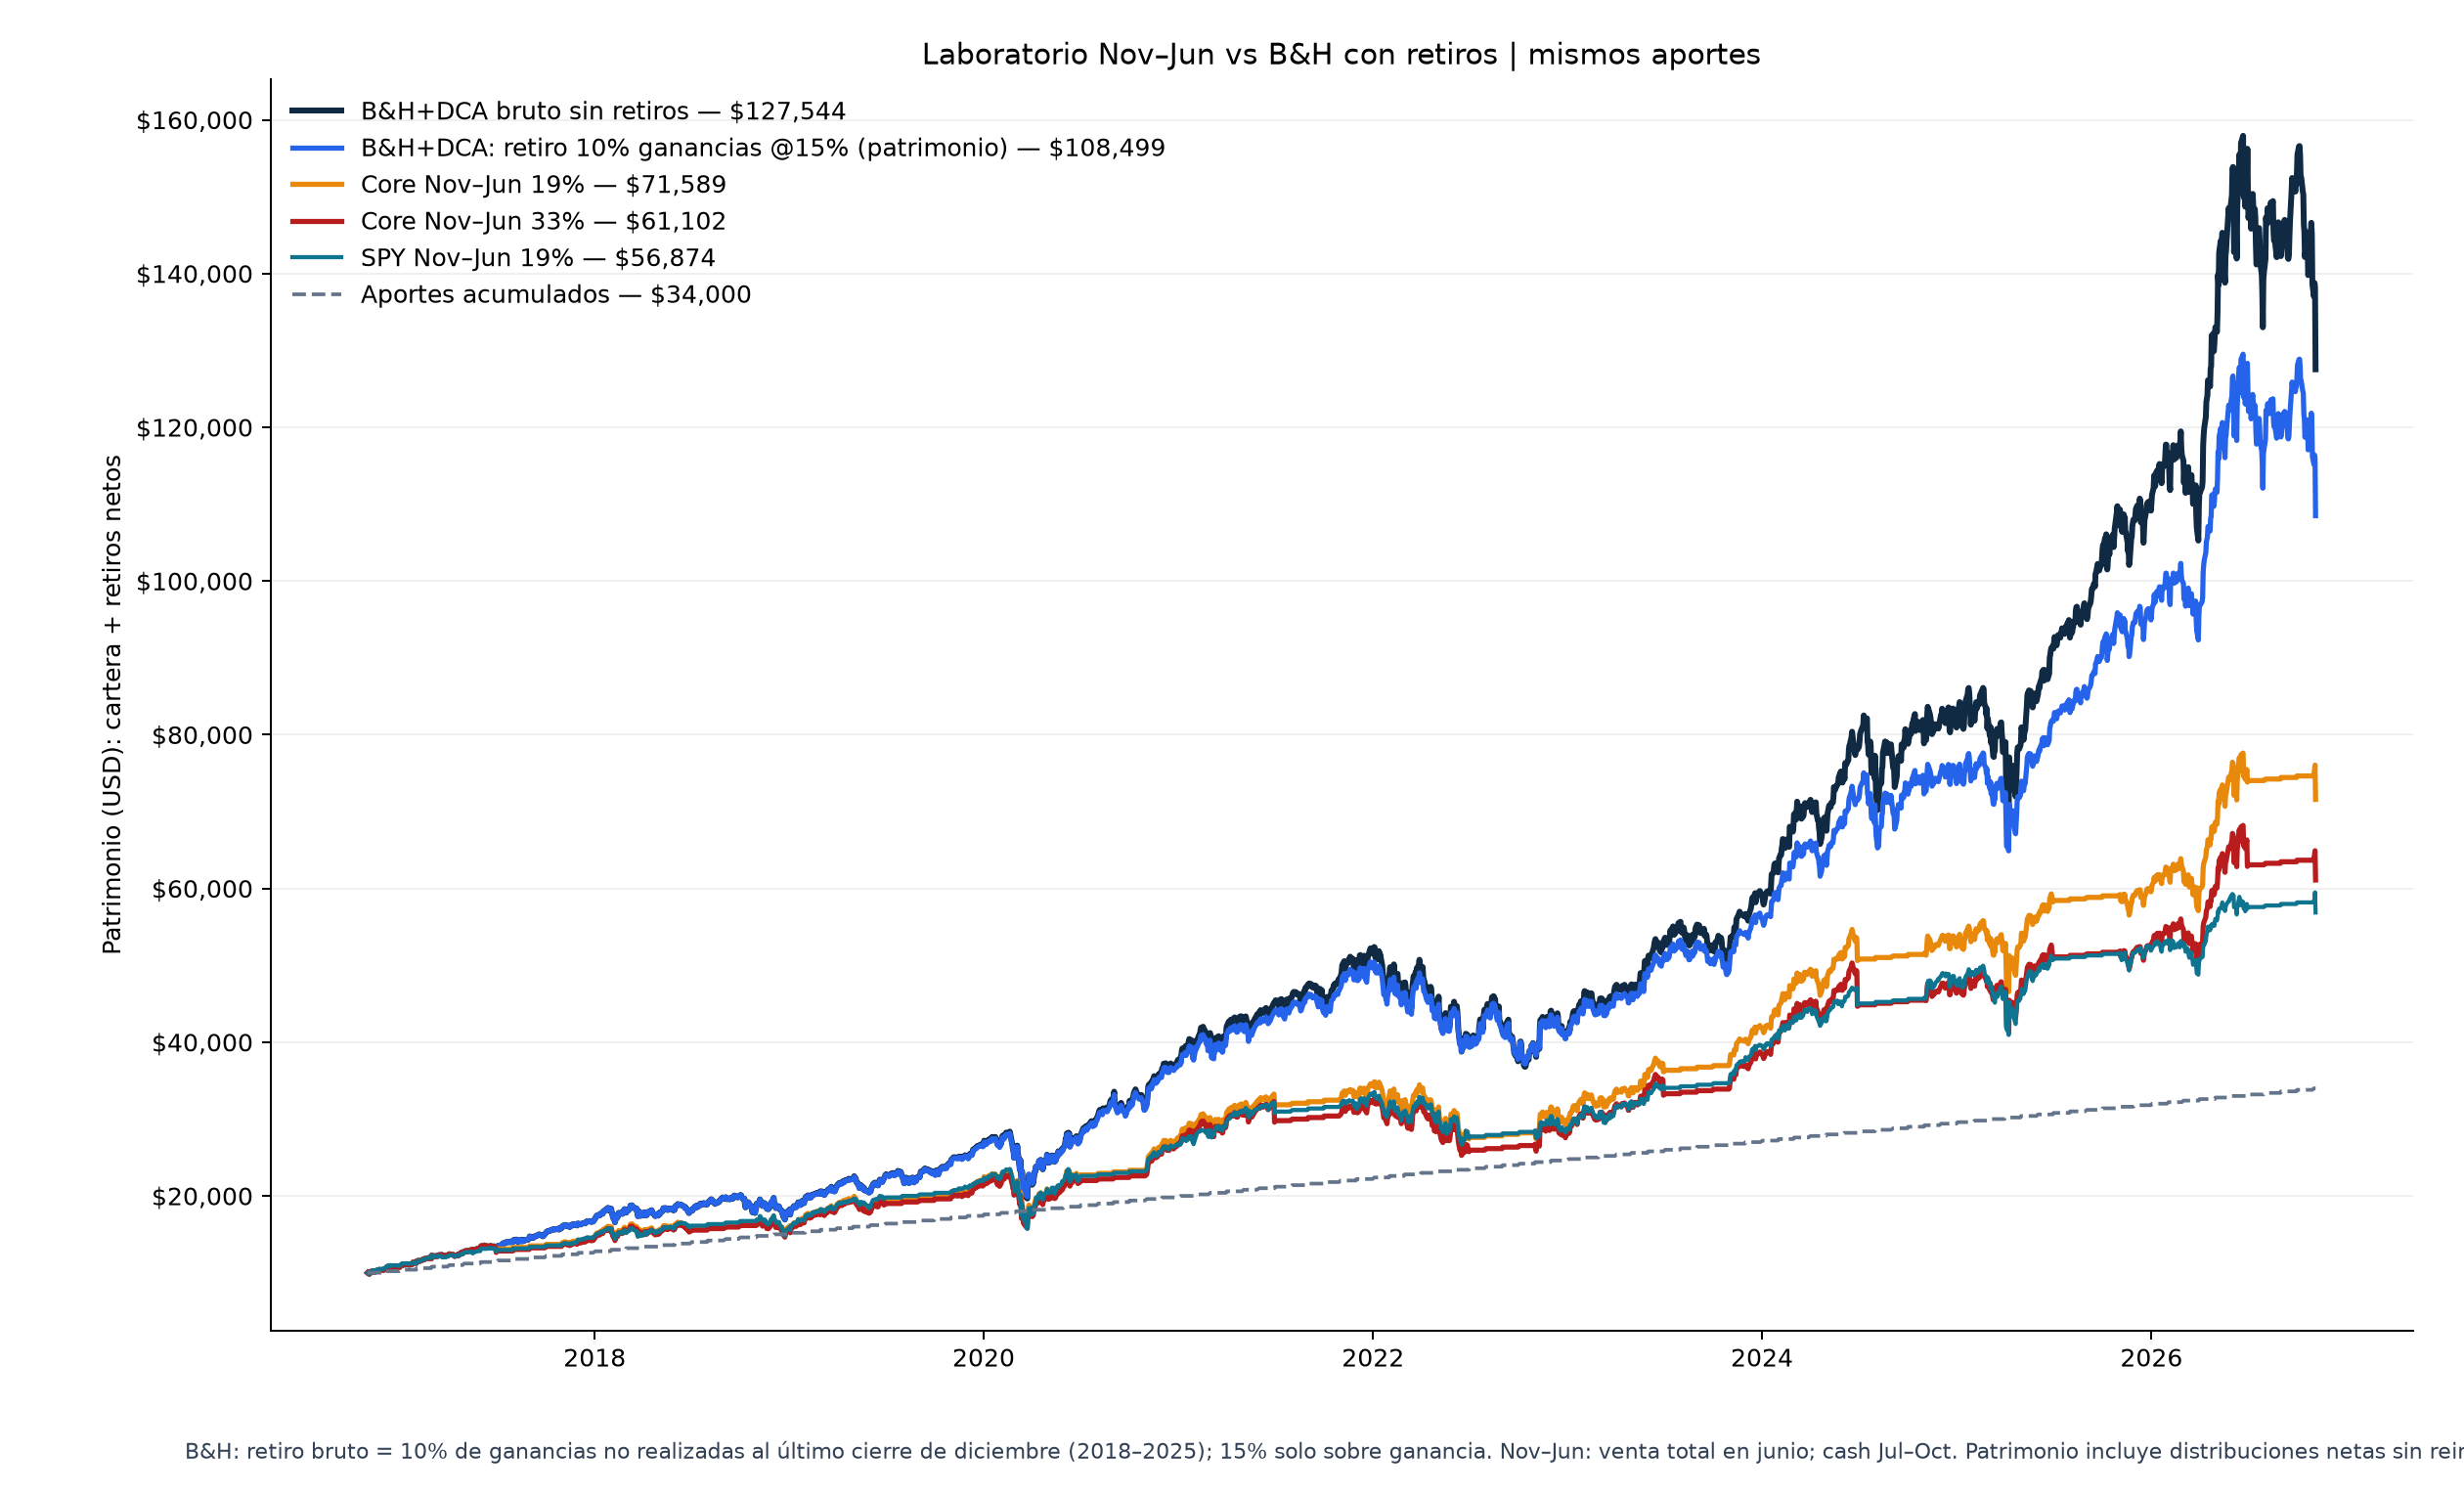

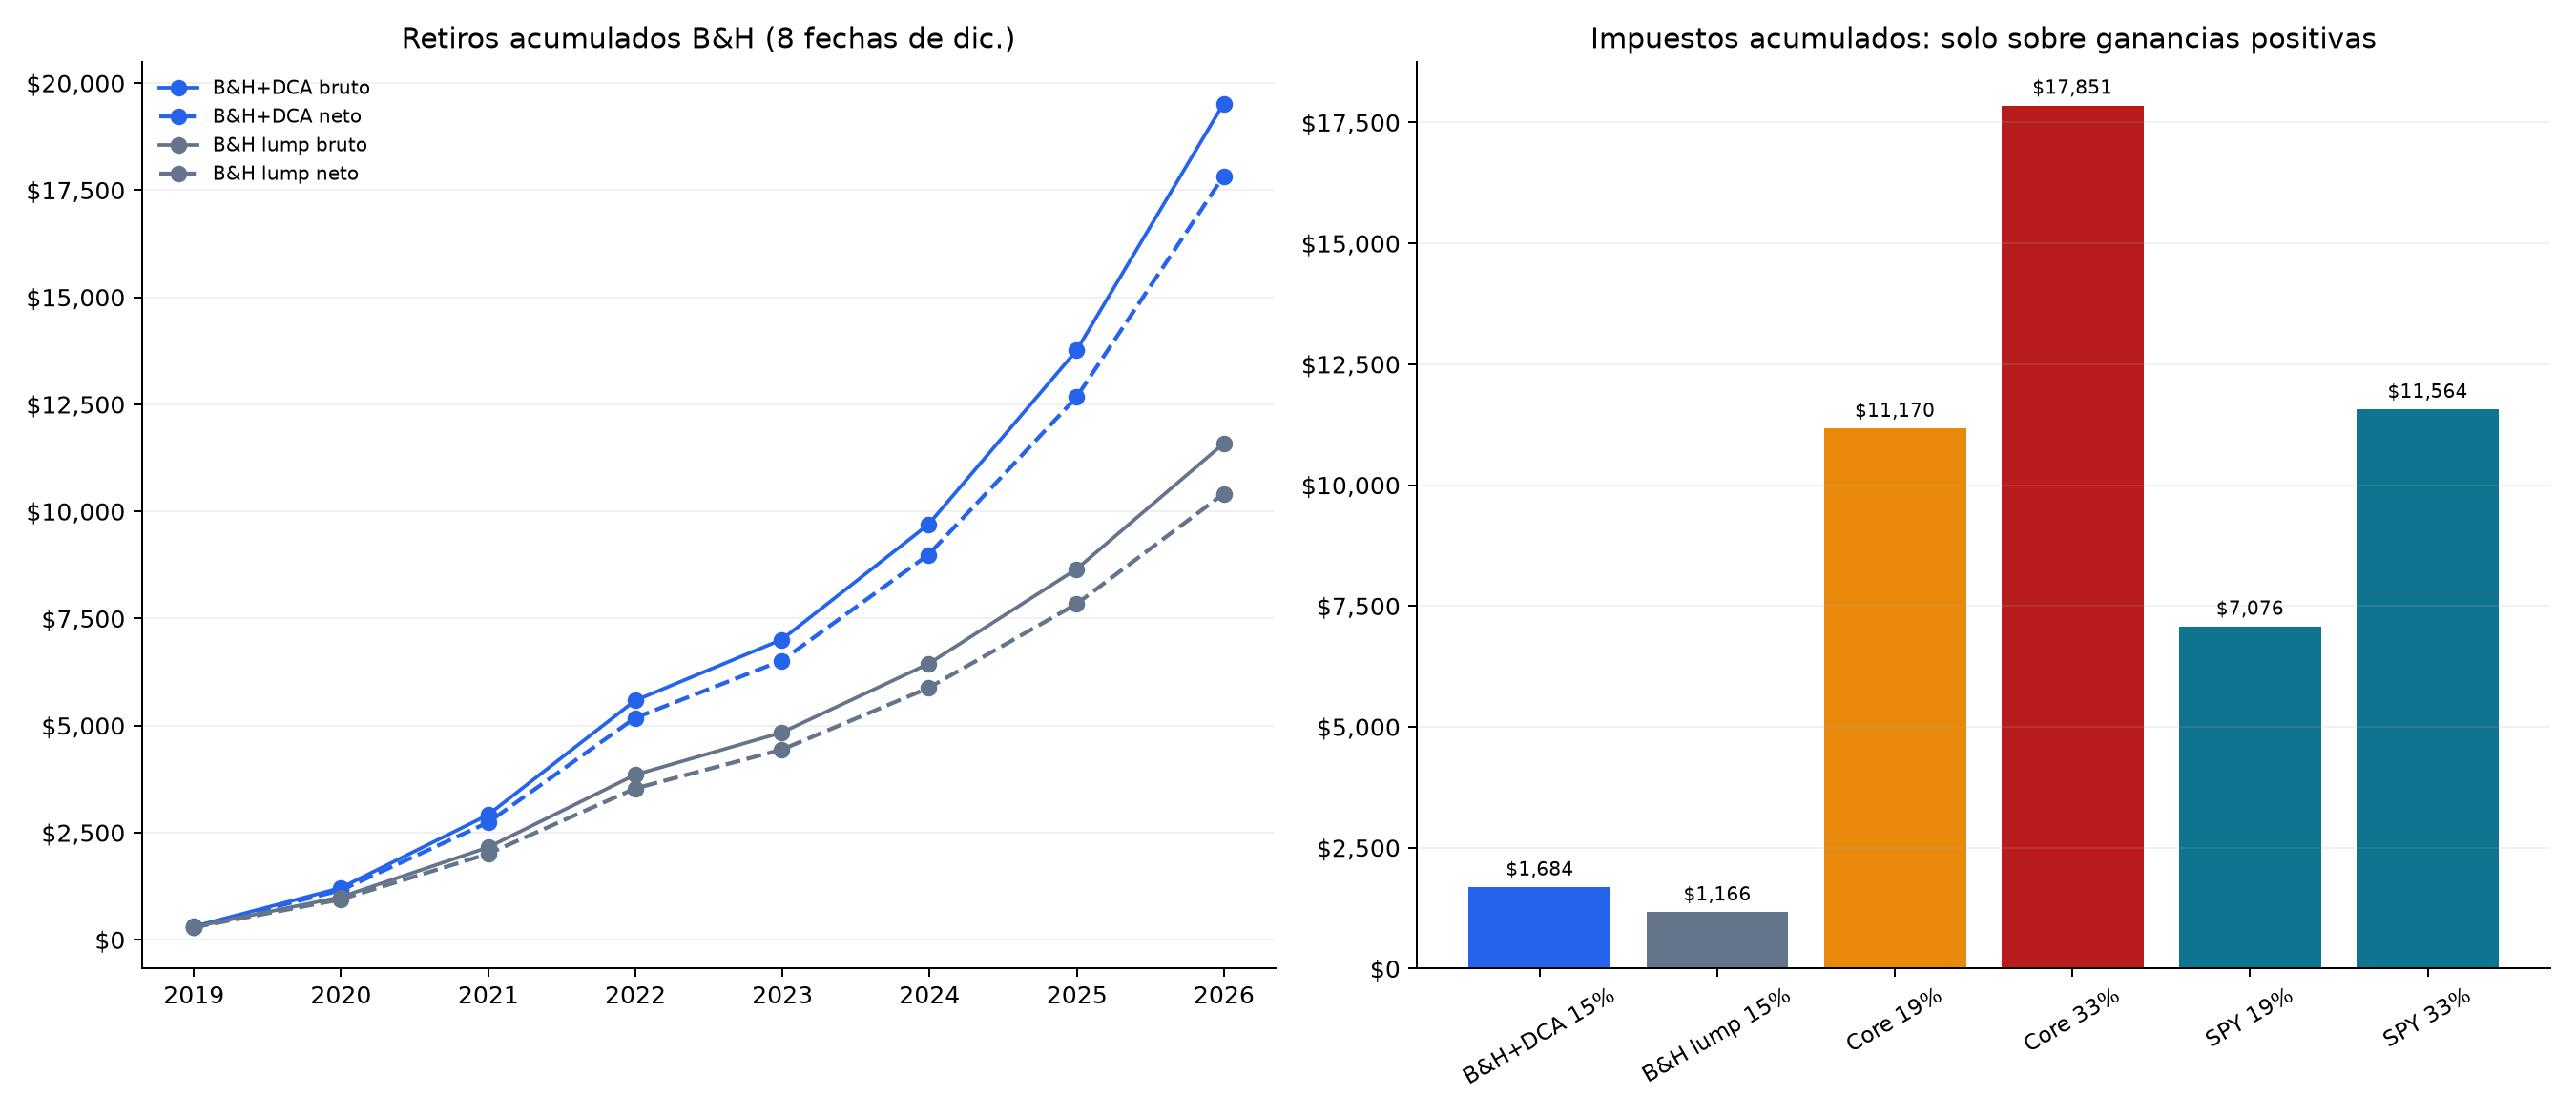

In [9]:
display(Image(filename=str(ROOT/'output/01_portfolio_value_co19_33.png')))
display(Image(filename=str(ROOT/'output/05_tax_withdrawals.png')))

In [10]:
# Auditoría de capital de las figuras finales de este mismo run.
for fig in ['01_portfolio_value_co19_33.png','05_tax_withdrawals.png','02_terminal_values.png']:
    p=ROOT/'output'/fig
    assert p.exists() and p.stat().st_size>100_00
    
print('Figuras presentes con outputs reales')
summary[['Cartera sin liquidar','Retiros netos retenidos','Patrimonio económico NO liquidado','Impuestos ya pagados']].loc[['core_bh_dca_withdraw_10pct_gains_15','core_nov_jun_tax_19','core_nov_jun_tax_33']].round(2)

Figuras presentes con outputs reales


,Cartera sin liquidar,Retiros netos retenidos,Patrimonio económico NO liquidado,Impuestos ya pagados
name,,,,
core_bh_dca_withdraw_10pct_gains_15,90669.54,17829.02,108498.56,1684.01
core_nov_jun_tax_19,71589.03,0.00,71589.03,11170.06
core_nov_jun_tax_33,61101.88,0.00,61101.88,17850.74


## 7. Cambios respecto a versiones antiguas

1. Antes B&H liquidaba al final: ahora **ocho distribuciones en dic-2018…dic-2025** y el capital restante continúa, por ello no deben compararse valores de versiones distintas.
2. El retiro es **bruto W=10%U** (con componente coste), no 15% de todo el retiro; impuesto solo sobre componente ganancia neto de comisión y coste imputado.
3. Base fiscal global `max(0,V−B)` compensa activos dentro de cada venta: cambia Nov–Jun respecto a versiones que sumaban clamp individual. No hay cambio en los datos para «mejorar» resultados.
4. Presentación anterior confundía “net liquidation” con patrimonio y contenía un campo auxiliar de original basis con cálculo intermedio obsoleto. Se sustituye por **coste remanente** y **reconciliación original: aportes-fee-coste devuelto**. XIRR ahora ordena por fecha eventos presentes en la misma fecha, sin alterar las observaciones.
5. Pospequeñas diferencias de XIRR respecto versiones anteriores vienen de eliminación de overlay terminal inexistente y flujos en su fecha. Las cifras actuales salen únicamente del motor en este notebook.

In [11]:
# Contraste de magnitudes finales CON TODOS LOS SUPUESTOS ACTUALES de este cuaderno.
# Versión previa retirada: solo para explicar mecánica, no se reutilizan sus cifras.
old_core19=71050.6008113235; old_core33=60325.47389956581
change=pd.DataFrame({'Escenario':['Core NovJun 19','Core NovJun 33'],
 'Cifra anterior provisional':[old_core19,old_core33],
 'Cifra actual global tax base':[nov19,nov33]})
change['Diferencia USD']=change['Cifra actual global tax base']-change['Cifra anterior provisional']
print('Cambio procede de la compensación global dentro de cada venta (no datos).')
change.round(2)

Cambio procede de la compensación global dentro de cada venta (no datos).


,Escenario,Cifra anterior provisional,Cifra actual global tax base,Diferencia USD
0,Core NovJun 19,71050.60,71589.03,538.43
1,Core NovJun 33,60325.47,61101.88,776.40


## 8. Conclusión y límites imprescindibles

En esta **reconstrucción a pesos actuales**, el B&H+DCA con plan de retiro conserva un patrimonio superior a Nov–Jun, pero **no refuta universalmente la estacionalidad ni demuestra una ley histórica**, por periodo, selección de activos y reglas fiscales simplificadas.

Límites: fuente pública ajustada y rebalanceo periódico a pesos de hoy (sesgo retrospectivo y composición); BRK.B fraccionado ideal; sin inflación, spreads cambiando, COP/tax legal ni tipo de cambio; dividendos reinvertidos y sin impuesto específico separado; cash retiro al 0% fuera de cartera; pérdidas fiscales no transportadas; tasas solo escenarios educativos; sin evaluación lote DCA <2 años; periodo parcial 2026 sin retiro; sin reinversión de cash distribuido. Tampoco concluimos falsedad del tuit de Trading Sharks: elegir años cada cuatro puede corresponder al ciclo electoral midterm y es otra prueba.

In [12]:
# Guardar salidas para inspección reproducible del cuaderno.
nb_out=ROOT/'artifacts/notebook'; nb_out.mkdir(parents=True,exist_ok=True)
# Round only exports intended for reading; never substitutes constants for calculations.
metrics.to_csv(nb_out/'metrics_notebook.csv')
withdrawals.to_csv(nb_out/'withdrawals_notebook.csv',index=False)
import shutil
for filename in ['01_portfolio_value_co19_33.png','05_tax_withdrawals.png','02_terminal_values.png']:
    shutil.copyfile(ROOT/'output'/filename,nb_out/filename)
validation={
 'recalculated':True,
 'dca_portfolio_rounded':float(bh.remaining_portfolio_net),
 'dca_withdrawals_net_rounded':float(bh.withdrawals_net),
 'dca_economic_wealth_exact':float(bh.net_terminal_value),
 'core_nov_jun_19_exact':float(metrics.loc['core_nov_jun_tax_19','net_terminal_value']),
 'core_nov_jun_33_exact':float(metrics.loc['core_nov_jun_tax_33','net_terminal_value']),
 'num_withdrawals_DCA':int(bh.withdrawal_count),
 'economic_wealth_liquidated':False,
 'terms':'Educational fiscal sensitivity; not a real account history, tax advice, or universal claim.'}
(nb_out/'validation_notebook.json').write_text(json.dumps(validation,indent=2))
print(json.dumps(validation,indent=2,ensure_ascii=False))

{
  "recalculated": true,
  "dca_portfolio_rounded": 90669.54210235663,
  "dca_withdrawals_net_rounded": 17829.017710160348,
  "dca_economic_wealth_exact": 108498.55981251698,
  "core_nov_jun_19_exact": 71589.02663681554,
  "core_nov_jun_33_exact": 61101.87883337479,
  "num_withdrawals_DCA": 8,
  "economic_wealth_liquidated": false,
  "terms": "Educational fiscal sensitivity; not a real account history, tax advice, or universal claim."
}
